# FIFA World Cup 2026 – Objective 1

## Task 1: Shooting Performance

**Team Member:** Diwash Khatri Chehetri  
**Student ID:** S398690

### Analytic Question

Did teams that reached the knockout stage have more shots on target than teams eliminated in the group stage?

In [21]:
# Import libraries required for data analysis
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

# Set random seed for reproducible sampling
np.random.seed(42)

print("Libraries imported successfully.")

Libraries imported successfully.


### 2. Data Loading

The FIFA World Cup 2026 attacking statistics dataset is loaded using pandas. This dataset contains team-level attacking performance statistics from the tournament.

In [22]:
# Load the FIFA World Cup 2026 attacking statistics dataset
df = pd.read_csv("../data/raw/FIFA_2026_Attacking_Statistics.csv")

print("Dataset loaded successfully.")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

# Display the first five rows
df.head()

Dataset loaded successfully.
Number of rows: 48
Number of columns: 15


,Rank,Team,Goals,Assists,Attempts At Goal,Attempts On Target,Off-Target Attempts,Attempts At Goal Conv. Rate (%),Attempts Inside the Penalty Area,Attempts Outside the Penalty Area,Headed Attempts at Goal,xG,xG Efficiency,Corners,Possession Control (%)
0,1,England,20,14,118,52,40,17,88,30,27,15.03,1.33x,40,50
1,1,France,20,18,139,59,59,14,77,62,10,16.78,1.19x,51,51
2,3,Argentina,19,12,115,46,49,17,66,49,22,15.45,1.23x,41,53
3,4,Spain,14,10,140,54,59,10,79,61,22,17.48,0.8x,54,58
4,4,Belgium,14,10,112,35,43,13,74,38,16,10.62,1.32x,24,46


### 3. Data Wrangling and Preparation

Before conducting the analysis, the dataset is inspected for column names, data types, missing values and duplicate records. This ensures that the data used in the statistical analysis is complete and reliable.

In [23]:
# Display all column names
print("Column names:")
print(df.columns.tolist())

# Check data types
print("\nData types:")
print(df.dtypes)

# Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# Check duplicate rows
print("\nNumber of duplicate rows:", df.duplicated().sum())

Column names:
['Rank', 'Team', 'Goals', 'Assists', 'Attempts At Goal', 'Attempts On Target', 'Off-Target Attempts', 'Attempts At Goal Conv. Rate (%)', 'Attempts Inside the Penalty Area', 'Attempts Outside the Penalty Area', 'Headed Attempts at Goal', 'xG', 'xG Efficiency', 'Corners', 'Possession Control (%)']

Data types:
Rank                                   int64
Team                                     str
Goals                                  int64
Assists                                int64
Attempts At Goal                       int64
Attempts On Target                     int64
Off-Target Attempts                    int64
Attempts At Goal Conv. Rate (%)        int64
Attempts Inside the Penalty Area       int64
Attempts Outside the Penalty Area      int64
Headed Attempts at Goal                int64
xG                                   float64
xG Efficiency                            str
Corners                                int64
Possession Control (%)                 int64
d

#### Data Quality Result

The dataset contains 48 teams and 15 variables. The data quality check found no missing values and no duplicate rows. The main variable used in this analysis, **Attempts On Target**, is stored as a numeric variable. Therefore, no rows need to be removed or imputed before further preparation and analysis.

### 4. Group Classification

To answer the analytic question, teams are classified into two groups:

- **Knockout Stage:** Teams that advanced from the group stage to the Round of 32.
- **Group Stage Eliminated:** Teams that did not advance to the Round of 32.

The 2026 tournament had 32 teams advancing to the knockout stage and 16 teams eliminated during the group stage.

In [24]:
# Teams that advanced to the Round of 32
knockout_teams = [
    "Mexico", "South Africa",
    "Switzerland", "Canada", "Bosnia-Herzegovina",
    "Brazil", "Morocco",
    "USA", "Australia", "Paraguay",
    "Germany", "Côte d'Ivoire", "Ecuador",
    "Netherlands", "Japan", "Sweden",
    "Belgium", "Egypt",
    "Spain", "Cabo Verde",
    "France", "Norway", "Senegal",
    "Argentina", "Austria", "Algeria",
    "Colombia", "Portugal", "DR Congo",
    "England", "Croatia", "Ghana"
]

# Create the Stage column
df["Stage"] = np.where(
    df["Team"].isin(knockout_teams),
    "Knockout Stage",
    "Group Stage Eliminated"
)

# Check the number of teams in each group
print(df["Stage"].value_counts())

Stage
Knockout Stage            30
Group Stage Eliminated    18
Name: count, dtype: int64


In [25]:
# Find knockout team names that do not exactly match the FIFA dataset
missing_teams = [team for team in knockout_teams if team not in df["Team"].values]

print("Names not matching the FIFA dataset:")
print(missing_teams)

Names not matching the FIFA dataset:
['Bosnia-Herzegovina', 'DR Congo']


In [26]:
# Correct the two team names to match the FIFA dataset
knockout_teams = [
    "Mexico", "South Africa",
    "Switzerland", "Canada", "Bosnia and Herzegovina",
    "Brazil", "Morocco",
    "USA", "Australia", "Paraguay",
    "Germany", "Côte d'Ivoire", "Ecuador",
    "Netherlands", "Japan", "Sweden",
    "Belgium", "Egypt",
    "Spain", "Cabo Verde",
    "France", "Norway", "Senegal",
    "Argentina", "Austria", "Algeria",
    "Colombia", "Portugal", "Congo DR",
    "England", "Croatia", "Ghana"
]

# Recreate the Stage column
df["Stage"] = np.where(
    df["Team"].isin(knockout_teams),
    "Knockout Stage",
    "Group Stage Eliminated"
)

# Verify group sizes
print(df["Stage"].value_counts())

Stage
Knockout Stage            32
Group Stage Eliminated    16
Name: count, dtype: int64


### 5. Population, Sample and Sampling Technique

**Population:** The population consists of all 48 teams that participated in the FIFA World Cup 2026.

**Sampling unit:** Each team represents one sampling unit.

**Groups:** The population is divided into 32 teams that reached the knockout stage and 16 teams that were eliminated in the group stage.

**Sampling technique:** Stratified random sampling is used. Teams are separated into the two tournament-stage groups first, and teams are then randomly sampled from each group. This ensures that both groups are represented in the analysis.

A fixed random seed (`42`) is used so that the same sample can be reproduced.

In [27]:
# Separate the population into the two groups
knockout_population = df[df["Stage"] == "Knockout Stage"]
eliminated_population = df[df["Stage"] == "Group Stage Eliminated"]

# Stratified random sampling
knockout_sample = knockout_population.sample(n=24, random_state=42)
eliminated_sample = eliminated_population.sample(n=12, random_state=42)

# Combine the two samples
sample_df = pd.concat([knockout_sample, eliminated_sample])

print("Total sample size:", len(sample_df))
print("\nSample size by group:")
print(sample_df["Stage"].value_counts())

Total sample size: 36

Sample size by group:
Stage
Knockout Stage            24
Group Stage Eliminated    12
Name: count, dtype: int64


### 6. Descriptive Statistics

Descriptive statistics are calculated for **Attempts On Target** to compare the shooting performance of knockout-stage teams with teams eliminated in the group stage. The statistics include sample size, mean, median, standard deviation, minimum, maximum and quartiles.

In [28]:
# Descriptive statistics for Attempts On Target by tournament stage
descriptive_stats = sample_df.groupby("Stage")["Attempts On Target"].agg(
    Count="count",
    Mean="mean",
    Median="median",
    Std_Dev="std",
    Minimum="min",
    Maximum="max"
)

descriptive_stats.round(2)

,Count,Mean,Median,Std_Dev,Minimum,Maximum
Stage,,,,,,
Group Stage Eliminated,12,8.75,8.0,3.86,2,15
Knockout Stage,24,24.58,21.5,15.06,3,59


In [29]:
# Quartiles for Attempts On Target
quartiles = sample_df.groupby("Stage")["Attempts On Target"].quantile(
    [0.25, 0.50, 0.75]
).unstack()

quartiles.columns = ["Q1", "Q2 (Median)", "Q3"]

quartiles.round(2)

,Q1,Q2 (Median),Q3
Stage,,,
Group Stage Eliminated,6.75,8.0,11.50
Knockout Stage,13.75,21.5,30.25


#### Descriptive Statistics Interpretation

The sampled knockout-stage teams recorded a higher mean number of attempts on target (24.58) than the sampled group-stage eliminated teams (8.75). The median was also higher for knockout-stage teams (21.50 compared with 8.00).

The knockout-stage group had a larger standard deviation (15.06), indicating greater variation in shooting performance among these teams. Overall, the descriptive statistics suggest that knockout-stage teams produced more attempts on target, but inferential statistical analysis is required to determine whether the difference is statistically significant.

### 7. Visualisation

A boxplot is used to compare the distribution of attempts on target between knockout-stage teams and group-stage eliminated teams.

# Prepare the two groups for visualisation
knockout_shots = knockout_sample["Attempts On Target"]
eliminated_shots = eliminated_sample["Attempts On Target"]

# Create boxplot
plt.figure(figsize=(8, 5))

plt.boxplot(
    [eliminated_shots, knockout_shots],
    tick_labels=["Group Stage Eliminated", "Knockout Stage"]
)

plt.title("Attempts on Target by Tournament Stage")
plt.ylabel("Attempts on Target")
plt.xlabel("Tournament Stage")
plt.grid(axis="y", alpha=0.3)

plt.show()

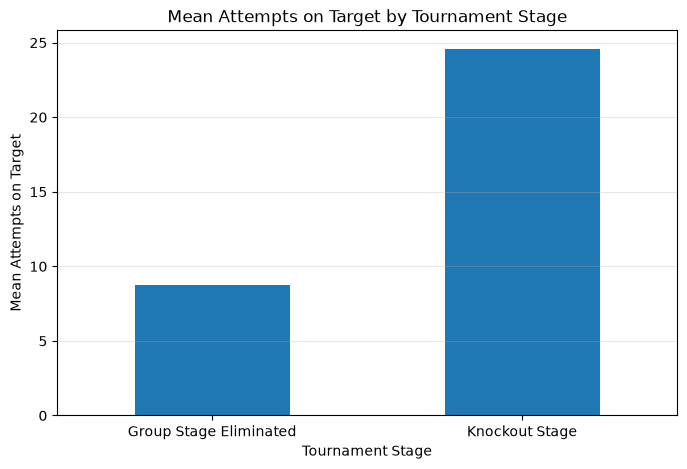

In [30]:
# Calculate group means
group_means = sample_df.groupby("Stage")["Attempts On Target"].mean()

# Create bar chart
plt.figure(figsize=(8, 5))

group_means.plot(kind="bar")

plt.title("Mean Attempts on Target by Tournament Stage")
plt.ylabel("Mean Attempts on Target")
plt.xlabel("Tournament Stage")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)

plt.show()

### 8. Inferential Statistics – 95% Confidence Interval

A 95% confidence interval is calculated for the difference in mean attempts on target between knockout-stage teams and group-stage eliminated teams.

The difference is calculated as:

**Knockout Stage Mean − Group Stage Eliminated Mean**

A Welch-based confidence interval is used because the two groups have different sample sizes and noticeably different standard deviations.

In [31]:
# Calculate sample statistics
mean_knockout = knockout_shots.mean()
mean_eliminated = eliminated_shots.mean()

var_knockout = knockout_shots.var(ddof=1)
var_eliminated = eliminated_shots.var(ddof=1)

n_knockout = len(knockout_shots)
n_eliminated = len(eliminated_shots)

# Difference between sample means
mean_difference = mean_knockout - mean_eliminated

# Standard error for Welch's method
standard_error = np.sqrt(
    (var_knockout / n_knockout) +
    (var_eliminated / n_eliminated)
)

# Welch-Satterthwaite degrees of freedom
df_welch = (
    (var_knockout / n_knockout + var_eliminated / n_eliminated) ** 2
) / (
    ((var_knockout / n_knockout) ** 2 / (n_knockout - 1)) +
    ((var_eliminated / n_eliminated) ** 2 / (n_eliminated - 1))
)

# Critical t-value for 95% confidence
t_critical = stats.t.ppf(0.975, df_welch)

# Confidence interval
margin_error = t_critical * standard_error

ci_lower = mean_difference - margin_error
ci_upper = mean_difference + margin_error

print("Mean difference:", round(mean_difference, 2))
print("95% CI:", (round(ci_lower, 2), round(ci_upper, 2)))
print("Welch degrees of freedom:", round(df_welch, 2))

Mean difference: 15.83
95% CI: (np.float64(9.14), np.float64(22.53))
Welch degrees of freedom: 28.43


In [32]:
# Define shooting data for both sampled groups
knockout_shots = knockout_sample["Attempts On Target"]
eliminated_shots = eliminated_sample["Attempts On Target"]

print("Knockout sample:", len(knockout_shots))
print("Eliminated sample:", len(eliminated_shots))

Knockout sample: 24
Eliminated sample: 12


### 9. Hypothesis Test – Welch's Two-Sample t-Test

A Welch's independent two-sample t-test is used because the two groups are independent, have different sample sizes, and have different standard deviations.

The hypotheses are:

**H₀ (Null Hypothesis):** Knockout-stage teams do not have a higher mean number of attempts on target than group-stage eliminated teams.

**H₁ (Alternative Hypothesis):** Knockout-stage teams have a higher mean number of attempts on target than group-stage eliminated teams.

The significance level is set at **α = 0.05**.

In [33]:
# Welch's two-sample t-test
t_stat, p_value = stats.ttest_ind(
    knockout_shots,
    eliminated_shots,
    equal_var=False,
    alternative="greater"
)

print("Welch's t-statistic:", round(t_stat, 3))
print("Degrees of freedom:", round(df_welch, 2))
print("p-value:", round(p_value, 5))

# Statistical decision
alpha = 0.05

if p_value < alpha:
    print("Decision: Reject H0")
else:
    print("Decision: Fail to reject H0")

Welch's t-statistic: 4.842
Degrees of freedom: 28.43
p-value: 2e-05
Decision: Reject H0


#### Statistical Interpretation

The Welch two-sample t-test produced a t-statistic of **4.842** with approximately **28.43 degrees of freedom** and a one-sided p-value of **0.00002**.

Since the p-value is less than the significance level of 0.05, the null hypothesis is rejected. There is statistically significant evidence that teams reaching the knockout stage had a higher mean number of attempts on target than teams eliminated in the group stage.

The estimated mean difference was **15.83 attempts on target**, with a 95% confidence interval from **9.14 to 22.53**. Since the entire confidence interval is above zero, it also supports the conclusion that knockout-stage teams recorded more attempts on target.

### 10. Conclusion

This analysis investigated whether FIFA World Cup 2026 teams that reached the knockout stage recorded more attempts on target than teams eliminated during the group stage.

Using a proportionate stratified random sample of **36 teams**, the knockout-stage teams had a mean of **24.58 attempts on target**, compared with **8.75** for group-stage eliminated teams.

The Welch two-sample t-test found a statistically significant difference (**t = 4.842, p = 0.00002**). The estimated difference between the two means was **15.83 attempts on target**, with a 95% confidence interval of **[9.14, 22.53]**.

Therefore, the analysis provides strong statistical evidence that teams reaching the knockout stage recorded more attempts on target than teams eliminated in the group stage.

#### Limitation

The dataset contains tournament-level team totals rather than attempts on target per individual match. Teams progressing further in the tournament generally played more matches, which may contribute to their higher total attempts on target. Therefore, the result demonstrates an association between tournament progression and total attempts on target, but should not be interpreted as evidence that knockout-stage teams necessarily produced more attempts on target per match.

In [34]:
# Save the prepared dataset with the Stage classification
df.to_csv("../data/cleaned/task1_shooting_cleaned.csv", index=False)

# Save the stratified sample used in the analysis
sample_df.to_csv("../outputs/results/task1_shooting_sample.csv", index=False)

print("Cleaned dataset and sample saved successfully.")

Cleaned dataset and sample saved successfully.


In [35]:
# Create a summary of the main statistical results
results = pd.DataFrame({
    "Measure": [
        "Knockout Stage Mean",
        "Group Stage Eliminated Mean",
        "Mean Difference",
        "95% CI Lower",
        "95% CI Upper",
        "Welch t-statistic",
        "Degrees of Freedom",
        "p-value"
    ],
    "Value": [
        mean_knockout,
        mean_eliminated,
        mean_difference,
        ci_lower,
        ci_upper,
        t_stat,
        df_welch,
        p_value
    ]
})

results.to_csv("../outputs/results/task1_statistical_results.csv", index=False)

results.round(4)

,Measure,Value
0,Knockout Stage Mean,24.5833
1,Group Stage Eliminated Mean,8.7500
2,Mean Difference,15.8333
3,95% CI Lower,9.1394
4,95% CI Upper,22.5272
5,Welch t-statistic,4.8419
6,Degrees of Freedom,28.4258
7,p-value,0.0000


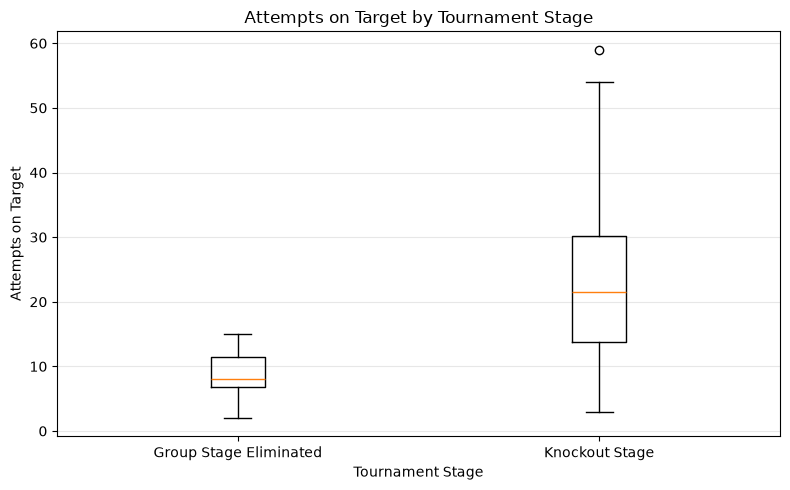

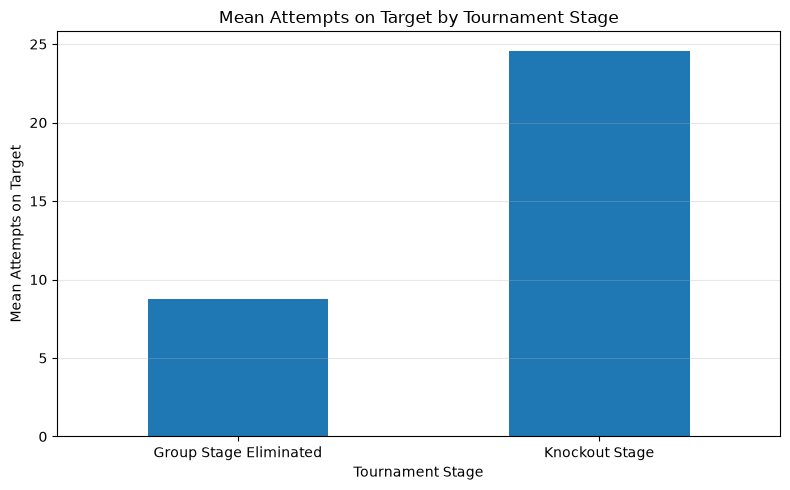

Charts saved successfully.


In [36]:
# Save Boxplot
plt.figure(figsize=(8, 5))

plt.boxplot(
    [eliminated_shots, knockout_shots],
    tick_labels=["Group Stage Eliminated", "Knockout Stage"]
)

plt.title("Attempts on Target by Tournament Stage")
plt.ylabel("Attempts on Target")
plt.xlabel("Tournament Stage")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("../outputs/charts/task1_shooting_boxplot.png", dpi=300)
plt.show()


# Save Mean Comparison Bar Chart
plt.figure(figsize=(8, 5))

group_means.plot(kind="bar")

plt.title("Mean Attempts on Target by Tournament Stage")
plt.ylabel("Mean Attempts on Target")
plt.xlabel("Tournament Stage")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("../outputs/charts/task1_shooting_mean_comparison.png", dpi=300)
plt.show()

print("Charts saved successfully.")